In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress 

## Problem 0: My own regression function

I wrote `my_regression(x, y)`, which returns the intercept and slope from linear
regression. I checked it against `linregress` from SciPy on a small dataset, and
both give the same intercept (0.05) and slope (1.99).

In [2]:
def my_regression(x, y):
    x_mean = np.mean(x)
    y_mean = np.mean(y)

    top = np.sum((x - x_mean) * (y - y_mean))   
    bottom = np.sum((x - x_mean) ** 2)         

    beta1 = top / bottom                        
    beta0 = y_mean - beta1 * x_mean          
    return beta0, beta1

x = np.array([1, 2, 3, 4, 5])
y = np.array([2.1, 3.9, 6.2, 7.8, 10.1])

b0, b1 = my_regression(x, y)
check = linregress(x, y)            # a prewritten function, for comparison

print("mine       :", b0, b1)
print("linregress :", check.intercept, check.slope)

mine       : 0.0500000000000016 1.9899999999999998
linregress : 0.0500000000000016 1.9899999999999998


## Problem 1: Left and right telencephalon

Note: this file has 20 subjects, not 21 as the assignment says, and it has no
`type` or `level` columns, so I used the `Telencephalon_L` and `Telencephalon_R`
rows directly.

In [3]:
url = "https://raw.githubusercontent.com/smart-stats/ds4bio_book/refs/heads/main/qbook/assets/kirby21.csv"
dat = pd.read_csv(url)

left_rows = dat[dat["roi"] == "Telencephalon_L"]
right_rows = dat[dat["roi"] == "Telencephalon_R"]
print("rows:", len(left_rows), len(right_rows))

same_order = (left_rows["id"].to_numpy() == right_rows["id"].to_numpy()).all()
print("same subjects, same order:", same_order)

left = left_rows["volume"].to_numpy()
right = right_rows["volume"].to_numpy()

rows: 20 20
same subjects, same order: True


Left -> Right: intercept -13875.9  slope 1.0442
Right -> Left: intercept 17150.4  slope 0.9501


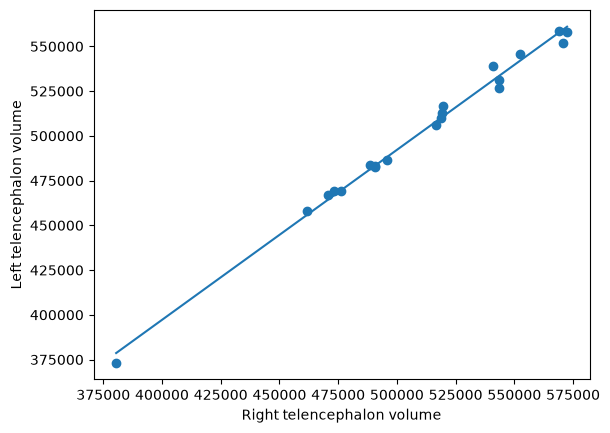

In [4]:
b0_lr, b1_lr = my_regression(left, right)
b0_rl, b1_rl = my_regression(right, left)

print("Left -> Right: intercept", round(b0_lr, 1), " slope", round(b1_lr, 4))
print("Right -> Left: intercept", round(b0_rl, 1), " slope", round(b1_rl, 4))

plt.scatter(right, left)
x_line = np.array([right.min(), right.max()])
plt.plot(x_line, b0_rl + b1_rl * x_line)
plt.xlabel("Right telencephalon volume")
plt.ylabel("Left telencephalon volume")
plt.show()

In [5]:
r = np.corrcoef(left, right)[0, 1]
print("1 / (left->right slope):", 1 / b1_lr)
print("right->left slope      :", b1_rl)
print("product of the slopes  :", b1_lr * b1_rl)
print("correlation squared    :", r ** 2)

1 / (left->right slope): 0.9576328482016253
right->left slope      : 0.9500552111008128
product of the slopes  : 0.9920871165655577
correlation squared    : 0.9920871165655578


## Problem 2: Regression Through Origin Model

The estimate of b̂ is divided by c. The formula is b̂ = (∑ X * Y) / (∑ X ^ 2).
If X is replaced with cX, the top becomes c times bigger
and the bottom becomes c squared times bigger.
So the new b̂ is (c / c squared) times the old one, which is the old b̂ divided by c.

For example, with X = 1, 2, 3 and Y = 2, 4, 7, the slope is 31/14 = 2.2143.
Doubling X (c = 2) gives 62/56 = 1.1071, exactly half. The code cell below shows the same
thing with the brain data: with c = 3 the slope goes from 1.0168 to 0.3389, which is 1.0168 / 3.

The fitted values stay the same, because the new slope times the
new X is (b̂ / c) times (cX), which equals b̂ times X. The slope changes only because
X is now measured in different units.

In [6]:
def origin_slope(x, y):
    return np.sum(x * y) / np.sum(x ** 2)

# The tiny example from above
x_small = np.array([1, 2, 3])
y_small = np.array([2, 4, 7])
print("c = 1:", origin_slope(x_small, y_small))        # 31/14
print("c = 2:", origin_slope(2 * x_small, y_small))    # 62/56

# The brain data, with c = 3
c = 3
print("original slope   :", origin_slope(left, right))
print("slope with c * X :", origin_slope(c * left, right))
print("original / c     :", origin_slope(left, right) / c)

c = 1: 2.2142857142857144
c = 2: 1.1071428571428572
original slope   : 1.0167702362924658
slope with c * X : 0.3389234120974886
original / c     : 0.3389234120974886


## Problem 3: A group indicator gives the group means

I made up data for 60 people: 30 in group 0 and 30 in group 1. The outcome is
about 3 higher on average in group 1, plus random noise.

I fit the line with my regression function from Problem 0, where X is 1 for
group 1 and 0 for group 0.

- At X = 0, the fitted value was 4.8119, which equals the group 0 mean of 4.8119.
- At X = 1, the fitted value was 7.8788, which equals the group 1 mean of 7.8788.

This happens because X is only 0 or 1: the fitted value for group 0 is just b0,
and for group 1 it is b0 + b1, and the best single prediction for a group under
squared error is that group's average. This is one simulated example, so it shows
the result holds here but is not a proof for every dataset.

In [7]:
np.random.seed(42)    

group = np.array([0] * 30 + [1] * 30)
outcome = 5 + 3 * group + np.random.normal(0, 1, 60)
b0, b1 = my_regression(group, outcome)
mean_0 = np.mean(outcome[:30])
mean_1 = np.mean(outcome[30:])

print("Fitted value at X = 0:", round(b0, 4), "| group 0 mean:", round(mean_0, 4))
print("Fitted value at X = 1:", round(b0 + b1, 4), "| group 1 mean:", round(mean_1, 4))

Fitted value at X = 0: 4.8119 | group 0 mean: 4.8119
Fitted value at X = 1: 7.8788 | group 1 mean: 7.8788


## Problem 4: Standardized slope equals the correlation

After dividing X and Y by their standard deviations, each one has a standard
deviation of 1. The code below confirms this (both print 1).

Dividing by a positive number only changes the units, so it does not change the
correlation. The correlation of the scaled variables is the same as the original
correlation.

The slope formula is: slope = correlation * (SD of Y / SD of X).
For the scaled variables both SDs are 1, so this becomes
slope = correlation * (1 / 1) = correlation.

The same reasoning works with X and Y swapped, because the correlation is the same
in either order. So the slope is the correlation whether I regress Y on X or X on Y.

The code shows this: the slope of right on left was 0.99604, the slope of left on
right was 0.99604, and the correlation of the original data was 0.99604.

In [8]:
sd_left = np.std(left, ddof=1)
sd_right = np.std(right, ddof=1)

left_scaled = left / sd_left
right_scaled = right / sd_right

print("SD of scaled left :", np.std(left_scaled, ddof=1))
print("SD of scaled right:", np.std(right_scaled, ddof=1))

slope_a = my_regression(left_scaled, right_scaled)[1]
slope_b = my_regression(right_scaled, left_scaled)[1]
correlation = np.corrcoef(left, right)[0, 1]

print("slope, right on left:", slope_a)
print("slope, left on right:", slope_b)
print("correlation         :", correlation)

SD of scaled left : 1.0000000000000002
SD of scaled right: 1.0
slope, right on left: 0.9960357004473067
slope, left on right: 0.9960357004473073
correlation         : 0.9960357004473072
